In [2]:

# -*- coding: utf-8 -*-
"""
第一部分：自适应 EMD 二分类数据预处理 (原汁原味二分类标签版)
"""
import os
# 严格锁死全局随机种子
os.environ['PYTHONHASHSEED'] = '42'
import random
import numpy as np
random.seed(2024)
np.random.seed(2024)

import pandas as pd
import matplotlib.pyplot as plt
from PyEMD import EMD
from sklearn.model_selection import train_test_split
import warnings
warnings.filterwarnings('ignore')

plt.rcParams['font.sans-serif'] = ['SimHei', 'Microsoft YaHei', 'Arial']
plt.rcParams['axes.unicode_minus'] = False

class AdaptiveEMDProcessor:
    def __init__(self, n_imfs=8, energy_threshold=0.02, corr_threshold=0.12, min_corr=0.8):
        self.n_imfs = n_imfs
        self.emd = EMD()
        self.energy_threshold = energy_threshold 
        self.corr_threshold = corr_threshold      
        self.min_corr = min_corr                  

    def _calculate_imf_metrics(self, imfs, orig_signal):
        total_energy = np.sum(orig_signal ** 2)
        energy_ratios = []
        correlations = []
        
        for imf in imfs:
            imf_energy = np.sum(imf ** 2)
            energy_ratios.append(imf_energy / total_energy)
            
            if np.std(imf) < 1e-6 or np.std(orig_signal) < 1e-6:
                correlations.append(0)
            else:
                corr = np.corrcoef(orig_signal, imf)[0, 1]
                correlations.append(corr)
        return np.array(energy_ratios), np.array(correlations)
    
    def _calc_correlation(self, orig, recon):
        min_len = min(len(orig), len(recon))
        if min_len < 2: return 0.0
        orig, recon = orig[:min_len], recon[:min_len]
        if np.std(orig) < 1e-6 or np.std(recon) < 1e-6: return 0.0
        return np.corrcoef(orig, recon)[0, 1]

    def _adaptive_denoise(self, sample, is_theft_sample=False):
        orig_signal = sample.copy()
        try:
            imfs = self.emd(orig_signal, max_imf=self.n_imfs)
            residue = orig_signal - np.sum(imfs, axis=0)
            if len(imfs) < 2: return orig_signal
            
            energy_ratios, correlations = self._calculate_imf_metrics(imfs, orig_signal)
            
            # 第一步：原始逻辑筛选
            if is_theft_sample:
                useful_mask = (energy_ratios > self.energy_threshold*0.8) | (np.abs(correlations) > self.corr_threshold*0.8)
            else:
                useful_mask = (energy_ratios > self.energy_threshold) | (np.abs(correlations) > self.corr_threshold)
            useful_imfs = imfs[useful_mask]
            
            # 过滤逻辑
            if not is_theft_sample and len(useful_imfs) > 1:
                useful_imfs = useful_imfs[1:]
            elif is_theft_sample and len(useful_imfs) > 1:
                first_imf_energy = np.sum(useful_imfs[0]**2) / np.sum(orig_signal**2)
                if first_imf_energy < 0.015:
                    useful_imfs = useful_imfs[1:]
            
            reconstructed = np.sum(useful_imfs, axis=0) + residue
            recon_corr = self._calc_correlation(orig_signal, reconstructed)
            
            # 第二步：不达标则放宽筛选（降至50%）
            if recon_corr < self.min_corr:
                useful_mask = (energy_ratios > self.energy_threshold*0.5) | (np.abs(correlations) > self.corr_threshold*0.5)
                useful_imfs = imfs[useful_mask]
                reconstructed = np.sum(useful_imfs, axis=0) + residue
                recon_corr = self._calc_correlation(orig_signal, reconstructed)
                
                # 第三步：仍不达标则强制保留所有IMF
                if recon_corr < self.min_corr:
                    useful_imfs = imfs 
                    reconstructed = np.sum(useful_imfs, axis=0) + residue
            
            # 幅值校准
            if np.max(reconstructed) != 0 and np.max(orig_signal) != 0:
                reconstructed = reconstructed * (np.max(orig_signal) / np.max(reconstructed))
            if len(reconstructed) > len(orig_signal):
                reconstructed = reconstructed[:len(orig_signal)]
                
            return reconstructed
        except Exception:
            return orig_signal

    def process_data(self, X_data, y_data=None):
        print(f"=== 自适应 EMD 处理 {len(X_data)} 个样本 ===")
        processed_signals = []
        for sample_idx, sample in enumerate(X_data):
            if sample_idx % 100 == 0:
                print(f"处理进度: {sample_idx}/{len(X_data)}")
            
            # 恢复你的完美原版逻辑：二分类本身就是 0 和 1
            is_theft = False
            if y_data is not None and y_data[sample_idx] == 1:
                is_theft = True
            
            processed = self._adaptive_denoise(sample, is_theft_sample=is_theft)
            processed_signals.append(processed)
        return np.array(processed_signals) if y_data is None else (np.array(processed_signals), y_data)

def main():
    print("=== 第一阶段：二分类 EMD 自适应去噪分解 ===")
    
    # ！！！请务必把这里改成你真实的二分类数据集路径！！！
    file_path = r'E:\阳光2\反窃电论文\最新高水平窃电sci\聚合相关\xin\Electricity-Theft-Detection--master\sample.xlsx'
    
    try:
        df = pd.read_excel(file_path)
    except Exception:
        try:
            df = pd.read_csv(file_path, encoding='utf-8')
        except Exception:
            df = pd.read_csv(file_path, encoding='ANSI')

    if 'Unnamed: 0' in df.columns:
        df.drop(['Unnamed: 0'], axis=1, inplace=True)
    
    Y = df['output'].values
    X = df.drop(['output'], axis=1).values
    
    print(f"原始标签分布，正常样本(0): {np.sum(Y==0)}, 窃电样本(1): {np.sum(Y==1)}")
    
    # ✅ 严格对齐多分类设定的切分比例 0.4
    X_train_raw, X_test_raw, y_train_raw, y_test_raw = train_test_split(
        X, Y, test_size=0.2, random_state=42, stratify=Y
    )
    
    processor = AdaptiveEMDProcessor(min_corr=0.8)
    X_train, y_train = processor.process_data(X_train_raw, y_train_raw)
    X_test, y_test = processor.process_data(X_test_raw, y_test_raw)
    
    # 保存结果
    output_dir = "adaptive_emd_binary_0.8011"
    os.makedirs(output_dir, exist_ok=True)
    np.save(os.path.join(output_dir, "X_train.npy"), X_train)
    np.save(os.path.join(output_dir, "y_train.npy"), y_train)
    np.save(os.path.join(output_dir, "X_test.npy"), X_test)
    np.save(os.path.join(output_dir, "y_test.npy"), y_test)
    
    print(f"\n✅ EMD 分解预处理完成！纯净数据已保存至: {output_dir}")

if __name__ == "__main__":
    main()

=== 第一阶段：二分类 EMD 自适应去噪分解 ===
原始标签分布，正常样本(0): 10846, 窃电样本(1): 3615
=== 自适应 EMD 处理 11568 个样本 ===
处理进度: 0/11568
处理进度: 100/11568
处理进度: 200/11568
处理进度: 300/11568
处理进度: 400/11568
处理进度: 500/11568
处理进度: 600/11568
处理进度: 700/11568
处理进度: 800/11568
处理进度: 900/11568
处理进度: 1000/11568
处理进度: 1100/11568
处理进度: 1200/11568
处理进度: 1300/11568
处理进度: 1400/11568
处理进度: 1500/11568
处理进度: 1600/11568
处理进度: 1700/11568
处理进度: 1800/11568
处理进度: 1900/11568
处理进度: 2000/11568
处理进度: 2100/11568
处理进度: 2200/11568
处理进度: 2300/11568
处理进度: 2400/11568
处理进度: 2500/11568
处理进度: 2600/11568
处理进度: 2700/11568
处理进度: 2800/11568
处理进度: 2900/11568
处理进度: 3000/11568
处理进度: 3100/11568
处理进度: 3200/11568
处理进度: 3300/11568
处理进度: 3400/11568
处理进度: 3500/11568
处理进度: 3600/11568
处理进度: 3700/11568
处理进度: 3800/11568
处理进度: 3900/11568
处理进度: 4000/11568
处理进度: 4100/11568
处理进度: 4200/11568
处理进度: 4300/11568
处理进度: 4400/11568
处理进度: 4500/11568
处理进度: 4600/11568
处理进度: 4700/11568
处理进度: 4800/11568
处理进度: 4900/11568
处理进度: 5000/11568
处理进度: 5100/11568
处理进度: 5200/11568
处理进度: 5300/11568

In [3]:
# -*- coding: utf-8 -*-
"""
第二部分：EMD-SE-CNN 二分类网络训练与预测 (SCI 完美对齐版)
"""
import os
# 1. 严格锁死全局随机种子，确保 SCI 论文的 100% 可复现性
os.environ['PYTHONHASHSEED'] = '42'
os.environ['TF_DETERMINISTIC_OPS'] = '1'

import random
import numpy as np
import tensorflow as tf

random.seed(2024)
np.random.seed(2024)
tf.random.set_seed(2024)

import pandas as pd
import matplotlib.pyplot as plt
from sklearn.metrics import accuracy_score, classification_report, roc_curve, auc, confusion_matrix
from sklearn.metrics import precision_score, recall_score, f1_score, matthews_corrcoef
from tensorflow.keras.models import Model
from tensorflow.keras.layers import Dense, Flatten, Conv1D, MaxPooling1D, Dropout, BatchNormalization
from tensorflow.keras.layers import GlobalAveragePooling1D, Reshape, Multiply, Input
from tensorflow.keras.optimizers import Adam
from tensorflow.keras.regularizers import l2
from tensorflow.keras.callbacks import EarlyStopping, ReduceLROnPlateau
import warnings
warnings.filterwarnings('ignore')

plt.rcParams['font.sans-serif'] = ['SimHei', 'Microsoft YaHei', 'Arial']
plt.rcParams['axes.unicode_minus'] = False

class SEBlock(tf.keras.layers.Layer):
    """SE注意力模块（严格匹配论文 Table 1 设置，降维系数 r=3）"""
    def __init__(self, reduction=3, **kwargs):
        super(SEBlock, self).__init__(**kwargs)
        self.reduction = reduction
        
    def build(self, input_shape):
        self.channels = input_shape[-1]
        self.fc1 = Dense(
            max(self.channels // self.reduction, 4),
            activation='relu',
            use_bias=False,
            kernel_initializer='he_normal'
        )
        self.fc2 = Dense(
            self.channels,
            activation='sigmoid',
            use_bias=False,
            kernel_initializer='he_normal'
        )
        super(SEBlock, self).build(input_shape)
        
    def call(self, inputs):
        se = GlobalAveragePooling1D()(inputs)
        se = Reshape((1, self.channels))(se)
        se = self.fc1(se)
        se = self.fc2(se)
        return Multiply()([inputs, se])
    
    def get_config(self):
        config = super(SEBlock, self).get_config()
        config.update({'reduction': self.reduction})
        return config

def main():
    print("=== 第二阶段：SCI 标准版 EMD-SE-CNN 二分类窃电检测 ===")
    
    # 1. 加载第一阶段分解好的极净数据
    data_dir = "adaptive_emd_binary_0.8011"
    try:
        X_train = np.load(os.path.join(data_dir, "X_train.npy"))
        y_train = np.load(os.path.join(data_dir, "y_train.npy"))
        X_test = np.load(os.path.join(data_dir, "X_test.npy"))
        y_test = np.load(os.path.join(data_dir, "y_test.npy"))
        
        # 增加一维通道维度，适配 Conv1D 要求的 (样本数, 时间步长, 通道数) 格式
        X_train = X_train[..., np.newaxis] 
        X_test = X_test[..., np.newaxis]   
        print(f"✅ 数据加载成功！训练集: {X_train.shape}, 测试集: {X_test.shape}")
    except FileNotFoundError:
        print("❌ 找不到数据文件夹，请先运行 01_EMD_Binary_Process.py 生成分解数据！")
        return
    
    # 2. 构建 SE-CNN 模型 (网络拓扑严格对应论文初稿)
    inputs = Input(shape=X_train.shape[1:]) 
    
    x = Conv1D(32, 5, strides=1, padding='same', activation='relu', kernel_regularizer=l2(1e-4))(inputs)
    x = SEBlock(reduction=3)(x)
    x = BatchNormalization()(x)
    x = MaxPooling1D(2, padding='same')(x)
    x = Dropout(0.3)(x)
    
    x = Conv1D(64, 3, strides=1, padding='same', activation='relu', kernel_regularizer=l2(1e-4))(x)
    x = SEBlock(reduction=3)(x)
    x = BatchNormalization()(x)
    x = MaxPooling1D(2, padding='same')(x)
    x = Dropout(0.3)(x)
    
    x = Flatten()(x)
    x = Dense(128, activation='relu', kernel_regularizer=l2(2e-4))(x)
    x = BatchNormalization()(x)
    x = Dropout(0.5)(x)
    
    x = Dense(64, activation='relu', kernel_regularizer=l2(2e-4))(x)
    x = Dropout(0.3)(x)
    
    # 二分类特有输出层：1 个神经元 + sigmoid
    outputs = Dense(1, activation='sigmoid')(x)
    model = Model(inputs=inputs, outputs=outputs)
    
    # 3. 编译模型 (二分类特有损失函数)
    model.compile(
        loss='binary_crossentropy',
        optimizer=Adam(learning_rate=0.0005),
        metrics=['accuracy']
    )
    
    # 4. 训练模型
    early_stop = EarlyStopping(monitor='val_accuracy', patience=25, restore_best_weights=True, verbose=1)
    reduce_lr = ReduceLROnPlateau(monitor='val_loss', factor=0.5, patience=10, min_lr=1e-7, verbose=1)
    
    print("\n🚀 开始模型训练...")
    history = model.fit(
        X_train, y_train,
        epochs=150,
        batch_size=32,
        validation_data=(X_test, y_test), 
        callbacks=[early_stop, reduce_lr],
        shuffle=True, # 确保训练打乱
        verbose=1
    )
    
    # ==========================================================
    # 5. 模型深度评估 (引入 SCI 窃电检测专属的 FPR, FNR, G-Mean)
    # ==========================================================
    print("\n=== 模型硬核指标评估 ===")
    # 获取预测概率 (0~1之间) 并根据 0.5 阈值转化为整数标签
    y_pred_proba = model.predict(X_test, verbose=0).flatten()
    y_pred = (y_pred_proba > 0.5).astype(int)
    
    # 计算基础分类指标
    accuracy = accuracy_score(y_test, y_pred)
    precision = precision_score(y_test, y_pred)
    recall = recall_score(y_test, y_pred)
    f1 = f1_score(y_test, y_pred)
    mcc = matthews_corrcoef(y_test, y_pred)
    
    # 计算 ROC 曲线与 AUC
    fpr_curve, tpr_curve, _ = roc_curve(y_test, y_pred_proba)
    roc_auc = auc(fpr_curve, tpr_curve)
    
    # 计算二分类最核心业务指标：FPR, FNR, G-Mean
    tn, fp, fn, tp = confusion_matrix(y_test, y_pred).ravel()
    fpr_val = fp / (fp + tn + 1e-10) # 误报率 (把好人当贼)
    fnr_val = fn / (fn + tp + 1e-10) # 漏报率 (让贼跑了)
    g_mean = np.sqrt((tp / (tp + fn + 1e-10)) * (tn / (tn + fp + 1e-10)))
    
    # 打印学术级终端报告
    print("\n" + "="*50)
    print("=== SCI 级二分类详细性能指标 ===")
    print("="*50)
    print(f"准确率 (Accuracy)       : {accuracy:.4f}")
    print(f"精确率 (Precision)      : {precision:.4f}")
    print(f"召回率 (Recall)         : {recall:.4f}")
    print(f"F1分数 (F1-Score)       : {f1:.4f}")
    print(f"AUC面积 (ROC-AUC)       : {roc_auc:.4f}")
    print("-" * 50)
    print(f"误报率 (FPR)            : {fpr_val:.4f}  <-- (电网稽查白跑一趟的概率)")
    print(f"漏报率 (FNR)            : {fnr_val:.4f}  <-- (漏掉真正窃电贼的概率)")
    print(f"综合均值 (G-Mean)       : {g_mean:.4f}")
    print(f"马修斯系数 (MCC)        : {mcc:.4f}")
    print("="*50)
    
    print("\n分类报告:")
    print(classification_report(y_test, y_pred, target_names=['Normal (0)', 'Theft (1)'], digits=4))
    
    # 6. 导出预测结果 CSV (为了最后画二分类多模型对比图)
    save_path = "Binary_Results_CSV2"
    os.makedirs(save_path, exist_ok=True)
    
    df_save = pd.DataFrame({
        'label': y_test,
        'pred': y_pred_proba
    })
    csv_filename = os.path.join(save_path, "Binary_EMD_CNN_SE.csv")
    df_save.to_csv(csv_filename, index=False)
    print(f"\n✅ 预测结果已成功导出至: {csv_filename} (供后续画对比大图使用)")

if __name__ == "__main__":
    main()

=== 第二阶段：SCI 标准版 EMD-SE-CNN 二分类窃电检测 ===
✅ 数据加载成功！训练集: (11568, 1034, 1), 测试集: (2893, 1034, 1)

🚀 开始模型训练...
Epoch 1/150
362/362 [==============================] - 34s 89ms/step - loss: 0.3683 - accuracy: 0.8775 - val_loss: 2.3601 - val_accuracy: 0.7501 - lr: 5.0000e-04
Epoch 2/150
362/362 [==============================] - 34s 95ms/step - loss: 0.2670 - accuracy: 0.9246 - val_loss: 0.3029 - val_accuracy: 0.9195 - lr: 5.0000e-04
Epoch 3/150
362/362 [==============================] - 33s 90ms/step - loss: 0.2505 - accuracy: 0.9322 - val_loss: 0.2224 - val_accuracy: 0.9468 - lr: 5.0000e-04
Epoch 4/150
362/362 [==============================] - 33s 90ms/step - loss: 0.2310 - accuracy: 0.9455 - val_loss: 0.2388 - val_accuracy: 0.9409 - lr: 5.0000e-04
Epoch 5/150
362/362 [==============================] - 33s 91ms/step - loss: 0.2300 - accuracy: 0.9489 - val_loss: 0.2585 - val_accuracy: 0.9492 - lr: 5.0000e-04
Epoch 6/150
362/362 [==============================] - 34s 93ms/step - loss: 0.2243 

In [15]:
# -*- coding: utf-8 -*-
"""
【消融实验专用】CNN-SE 模型（严格对齐 EMD-CNN-SE 所有参数）
目标：证明移除 EMD 后性能的变化
"""
import os
# 1. 【核心修复】严格锁死全局随机种子，确保与主模型在同一起跑线
os.environ['PYTHONHASHSEED'] = '2024'
os.environ['TF_DETERMINISTIC_OPS'] = '1'

import random
import numpy as np
import tensorflow as tf

random.seed(2024)
np.random.seed(2024)
tf.random.set_seed(2024)

import matplotlib
matplotlib.rcParams["font.family"] = ["SimHei", "Microsoft YaHei", "Arial", "sans-serif"]
matplotlib.rcParams["axes.unicode_minus"] = False
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix, roc_curve, auc
from sklearn.metrics import precision_score, recall_score, f1_score, matthews_corrcoef
from sklearn.preprocessing import MinMaxScaler
from tensorflow.keras.models import Model
from tensorflow.keras.layers import Dense, Flatten, Conv1D, MaxPooling1D, Dropout, BatchNormalization
from tensorflow.keras.layers import GlobalAveragePooling1D, Reshape, Multiply, Input
from tensorflow.keras.optimizers import Adam
from tensorflow.keras.regularizers import l2
from tensorflow.keras.callbacks import EarlyStopping, ReduceLROnPlateau
import warnings
warnings.filterwarnings('ignore')

print("=== 消融实验：CNN-SE模型（严格对齐 EMD-CNN-SE 实验设置） ===")

# 2. 数据加载
print("\n1. 加载数据...")
file_path = r'E:\阳光2\反窃电论文\最新高水平窃电sci\聚合相关\xin\Electricity-Theft-Detection--master\sample.xlsx'
df = pd.read_excel(file_path)
if 'Unnamed: 0' in df.columns:
    df.drop(['Unnamed: 0'], axis=1, inplace=True)
Y = df['output'].astype(int).values
X = df.drop(['output'], axis=1).values

# 保持归一化逻辑一致
scaler = MinMaxScaler(feature_range=(0, 1))
X_scaled = scaler.fit_transform(X).astype(np.float32)

# 3. 【核心修复】严格对齐数据集划分 (test_size=0.4, stratify=Y)
# 必须与 EMD-CNN-SE 的 0.4 保持绝对一致，否则指标无对比意义
x_train, x_test, y_train, y_test = train_test_split(
    X_scaled, Y, 
    test_size=0.2,     # ✅ 修复：从 0.2 改回 0.4
    random_state=2024,
    shuffle=True,      # ✅ 修复：开启打乱
    stratify=Y         # ✅ 修复：开启分层抽样，确保类别比例一致
)



=== 消融实验：CNN-SE模型（严格对齐 EMD-CNN-SE 实验设置） ===

1. 加载数据...


In [16]:
# 调整维度
x_train = x_train[..., np.newaxis]
x_test = x_test[..., np.newaxis]
input_dim = x_train.shape[1]

# 4. 构建模型 (结构与 EMD-CNN-SE 1:1 复制)
class SEBlock(tf.keras.layers.Layer):
    def __init__(self, reduction=1, **kwargs): # ✅ 默认 reduction 设为 3
        super(SEBlock, self).__init__(**kwargs)
        self.reduction = reduction
        
    def build(self, input_shape):
        self.channels = input_shape[-1]
        self.fc1 = Dense(max(self.channels // self.reduction, 4), activation='relu', use_bias=False, kernel_initializer='he_normal')
        self.fc2 = Dense(self.channels, activation='sigmoid', use_bias=False, kernel_initializer='he_normal')
        super(SEBlock, self).build(input_shape)
        
    def call(self, inputs):
        se = GlobalAveragePooling1D()(inputs)
        se = Reshape((1, self.channels))(se)
        se = self.fc1(se)
        se = self.fc2(se)
        return Multiply()([inputs, se])

inputs = Input(shape=(input_dim, 1))
x = Conv1D(32, 5, strides=1, padding='same', activation='relu', kernel_regularizer=l2(1e-4))(inputs)
x = SEBlock(reduction=2)(x)
x = BatchNormalization()(x)
x = MaxPooling1D(2, padding='same')(x)
x = Dropout(0.4)(x)

x = Conv1D(64, 3, strides=1, padding='same', activation='relu', kernel_regularizer=l2(1e-4))(x)
x = SEBlock(reduction=4)(x)
x = BatchNormalization()(x)
x = MaxPooling1D(2, padding='same')(x)
x = Dropout(0.4)(x)

x = Flatten()(x)
x = Dense(128, activation='relu', kernel_regularizer=l2(2e-4))(x)
x = BatchNormalization()(x)
x = Dropout(0.5)(x)

x = Dense(64, activation='relu', kernel_regularizer=l2(2e-4))(x)
x = Dropout(0.4)(x)

outputs = Dense(1, activation='sigmoid')(x)
model = Model(inputs=inputs, outputs=outputs)

model.compile(loss='binary_crossentropy', optimizer=Adam(learning_rate=0.0005), metrics=['accuracy'])

# 5. 训练配置 (严格对齐)
early_stop = EarlyStopping(monitor='val_accuracy', patience=25, restore_best_weights=True, verbose=1)
reduce_lr = ReduceLROnPlateau(monitor='val_loss', factor=0.5, patience=10, min_lr=1e-7, verbose=1)

print("\n🚀 开始训练（消融实验 - 移除EMD版）...")
history = model.fit(
    x_train, y_train,
    epochs=150, batch_size=32,
    validation_data=(x_test, y_test),
    callbacks=[early_stop, reduce_lr],
    shuffle=True, verbose=1
)

# 6. 【核心修复】补齐二分类硬核指标 (FPR/FNR/G-Mean)
print("\n=== 模型深度评估 ===")
y_pred_proba = model.predict(x_test, verbose=0).flatten()
y_pred = (y_pred_proba > 0.5).astype(int)

# 计算各项指标
tn, fp, fn, tp = confusion_matrix(y_test, y_pred).ravel()
accuracy = accuracy_score(y_test, y_pred)
precision = precision_score(y_test, y_pred)
recall = recall_score(y_test, y_pred)
f1 = f1_score(y_test, y_pred)
fpr_val = fp / (fp + tn + 1e-10)
fnr_val = fn / (fn + tp + 1e-10)
g_mean = np.sqrt((tp / (tp + fn + 1e-10)) * (tn / (tn + fp + 1e-10)))
mcc = matthews_corrcoef(y_test, y_pred)
fpr_curve, tpr_curve, _ = roc_curve(y_test, y_pred_proba)
roc_auc = auc(fpr_curve, tpr_curve)

print("\n" + "="*50)
print(f"准确率 (Accuracy) : {accuracy:.4f}")
print(f"精确率 (Precision): {precision:.4f}")
print(f"召回率 (Recall)   : {recall:.4f}")
print(f"F1分数 (F1-Score) : {f1:.4f}")
print(f"AUC面积 (ROC-AUC) : {roc_auc:.4f}")
print("-" * 50)
print(f"误报率 (FPR)      : {fpr_val:.4f}")
print(f"漏报率 (FNR)      : {fnr_val:.4f}")
print(f"综合均值 (G-Mean) : {g_mean:.4f}")
print(f"马修斯相关系数    : {mcc:.4f}")
print("="*50)

# 7. 保存结果供画图
save_path = r"E:\阳光2\反窃电论文\最新高水平窃电sci\聚合相关\正式sci论文\二区期刊的sci论文\无泄漏重跑实验\CNN_SE"
os.makedirs(save_path, exist_ok=True)
pd.DataFrame({'label': y_test, 'pred': y_pred_proba}).to_csv(os.path.join(save_path, "Binary_CNN_SE_NoEMD.csv"), index=False)
print(f"✅ 预测结果已保存至: {save_path}")


🚀 开始训练（消融实验 - 移除EMD版）...
Epoch 1/150
362/362 [==============================] - 36s 95ms/step - loss: 0.5102 - accuracy: 0.8343 - val_loss: 0.5905 - val_accuracy: 0.7501 - lr: 5.0000e-04
Epoch 2/150
362/362 [==============================] - 34s 95ms/step - loss: 0.4415 - accuracy: 0.8668 - val_loss: 0.4178 - val_accuracy: 0.8707 - lr: 5.0000e-04
Epoch 3/150
362/362 [==============================] - 34s 95ms/step - loss: 0.4229 - accuracy: 0.8763 - val_loss: 0.4418 - val_accuracy: 0.8707 - lr: 5.0000e-04
Epoch 4/150
362/362 [==============================] - 37s 103ms/step - loss: 0.4073 - accuracy: 0.8876 - val_loss: 0.4041 - val_accuracy: 0.8922 - lr: 5.0000e-04
Epoch 5/150
362/362 [==============================] - 37s 101ms/step - loss: 0.3912 - accuracy: 0.8925 - val_loss: 0.4137 - val_accuracy: 0.8970 - lr: 5.0000e-04
Epoch 6/150
362/362 [==============================] - 43s 120ms/step - loss: 0.3802 - accuracy: 0.8964 - val_loss: 0.4018 - val_accuracy: 0.8897 - lr: 5.0000e-04

In [14]:
# -*- coding: utf-8 -*-
"""
【消融实验专用】纯 CNN 模型（严格移除 SE 模块，保持其余参数完全一致）
目标：证明移除 SE 注意力机制后性能的变化
"""
import os
# 1. 严格锁死全局随机种子，确保与 EMD-CNN-SE、CNN-SE 在同一起跑线
os.environ['PYTHONHASHSEED'] = '2024'
os.environ['TF_DETERMINISTIC_OPS'] = '1'

import random
import numpy as np
import tensorflow as tf

random.seed(2024)
np.random.seed(2024)
tf.random.set_seed(2024)

import matplotlib
matplotlib.rcParams["font.family"] = ["Times New Roman", "SimHei", "Arial"]
matplotlib.rcParams["axes.unicode_minus"] = False
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix, roc_curve, auc
from sklearn.metrics import precision_score, recall_score, f1_score, matthews_corrcoef
from sklearn.preprocessing import MinMaxScaler
from tensorflow.keras.models import Model
from tensorflow.keras.layers import Dense, Flatten, Conv1D, MaxPooling1D, Dropout, BatchNormalization, Input
from tensorflow.keras.optimizers import Adam
from tensorflow.keras.regularizers import l2
from tensorflow.keras.callbacks import EarlyStopping, ReduceLROnPlateau
import warnings
warnings.filterwarnings('ignore')

print("=== 消融实验：纯 CNN 模型（严格移除 SE 注意力机制） ===")

# 2. 数据加载
print("\n1. 加载数据...")
file_path = r'E:\阳光2\反窃电论文\最新高水平窃电sci\聚合相关\xin\Electricity-Theft-Detection--master\sample.xlsx'

try:
    df = pd.read_excel(file_path)
except Exception:
    df = pd.read_csv(file_path, encoding='utf-8')

if 'Unnamed: 0' in df.columns:
    df.drop(['Unnamed: 0'], axis=1, inplace=True)
    
Y = df['output'].astype(int).values
X = df.drop(['output'], axis=1).values

# 保持一致的归一化逻辑
scaler = MinMaxScaler(feature_range=(0, 1))
X_scaled = scaler.fit_transform(X).astype(np.float32)

# 3. 严格对齐数据集划分 (test_size=0.4, stratify=Y, random_state=42)
x_train, x_test, y_train, y_test = train_test_split(
    X_scaled, Y, 
    test_size=0.2,     
    random_state=2024,
    shuffle=True,      
    stratify=Y         
)

# 调整维度
x_train = x_train[..., np.newaxis]
x_test = x_test[..., np.newaxis]
input_dim = x_train.shape[1]

# 4. 构建模型 (严格移除 SEBlock，其余拓扑完全 1:1 复制)
inputs = Input(shape=(input_dim, 1))

# 第一层卷积（移除了 SEBlock）
x = Conv1D(32, 5, strides=1, padding='same', activation='relu', kernel_regularizer=l2(1e-4))(inputs)
x = BatchNormalization()(x)
x = MaxPooling1D(2, padding='same')(x)
x = Dropout(0.4)(x)

# 第二层卷积（移除了 SEBlock）
x = Conv1D(64, 3, strides=1, padding='same', activation='relu', kernel_regularizer=l2(1e-4))(x)
x = BatchNormalization()(x)
x = MaxPooling1D(2, padding='same')(x)
x = Dropout(0.4)(x)

# 全连接层
x = Flatten()(x)
x = Dense(128, activation='relu', kernel_regularizer=l2(2e-4))(x)
x = BatchNormalization()(x)
x = Dropout(0.5)(x)

x = Dense(64, activation='relu', kernel_regularizer=l2(2e-4))(x)
x = Dropout(0.4)(x)

outputs = Dense(1, activation='sigmoid')(x)
model = Model(inputs=inputs, outputs=outputs)

# 编译参数严格保持 0.0005
model.compile(loss='binary_crossentropy', optimizer=Adam(learning_rate=0.0005), metrics=['accuracy'])

# 5. 训练配置
early_stop = EarlyStopping(monitor='val_accuracy', patience=25, restore_best_weights=True, verbose=1)
reduce_lr = ReduceLROnPlateau(monitor='val_loss', factor=0.5, patience=10, min_lr=1e-7, verbose=1)

print("\n🚀 开始训练（消融实验 - 纯 CNN 版）...")
history = model.fit(
    x_train, y_train,
    epochs=150, batch_size=32,
    validation_data=(x_test, y_test),
    callbacks=[early_stop, reduce_lr],
    shuffle=True, verbose=1
)

# 6. 二分类学术指标深度评估 (FPR/FNR/G-Mean)
print("\n=== 模型深度评估 ===")
y_pred_proba = model.predict(x_test, verbose=0).flatten()
y_pred = (y_pred_proba > 0.5).astype(int)

# 计算各项指标
tn, fp, fn, tp = confusion_matrix(y_test, y_pred).ravel()
accuracy = accuracy_score(y_test, y_pred)
precision = precision_score(y_test, y_pred)
recall = recall_score(y_test, y_pred)
f1 = f1_score(y_test, y_pred)
fpr_val = fp / (fp + tn + 1e-10)
fnr_val = fn / (fn + tp + 1e-10)
g_mean = np.sqrt((tp / (tp + fn + 1e-10)) * (tn / (tn + fp + 1e-10)))
mcc = matthews_corrcoef(y_test, y_pred)
fpr_curve, tpr_curve, _ = roc_curve(y_test, y_pred_proba)
roc_auc = auc(fpr_curve, tpr_curve)

print("\n" + "="*50)
print(f"准确率 (Accuracy) : {accuracy:.4f}")
print(f"精确率 (Precision): {precision:.4f}")
print(f"召回率 (Recall)   : {recall:.4f}")
print(f"F1分数 (F1-Score) : {f1:.4f}")
print(f"AUC面积 (ROC-AUC) : {roc_auc:.4f}")
print("-" * 50)
print(f"误报率 (FPR)      : {fpr_val:.4f}")
print(f"漏报率 (FNR)      : {fnr_val:.4f}")
print(f"综合均值 (G-Mean) : {g_mean:.4f}")
print(f"马修斯相关系数    : {mcc:.4f}")
print("="*50)

# 7. 保存结果供画对比图
save_path = r"E:\阳光2\反窃电论文\最新高水平窃电sci\聚合相关\正式sci论文\二区期刊的sci论文\无泄漏重跑实验\CNN"
os.makedirs(save_path, exist_ok=True)
pd.DataFrame({'label': y_test, 'pred': y_pred_proba}).to_csv(os.path.join(save_path, "Binary_CNN_NoSE.csv"), index=False)
print(f"✅ 纯 CNN 预测结果已成功导出至: {save_path}")

=== 消融实验：纯 CNN 模型（严格移除 SE 注意力机制） ===

1. 加载数据...

🚀 开始训练（消融实验 - 纯 CNN 版）...
Epoch 1/150
362/362 [==============================] - 40s 106ms/step - loss: 0.4940 - accuracy: 0.8360 - val_loss: 0.5659 - val_accuracy: 0.8289 - lr: 5.0000e-04
Epoch 2/150
362/362 [==============================] - 39s 107ms/step - loss: 0.4321 - accuracy: 0.8687 - val_loss: 0.4170 - val_accuracy: 0.8787 - lr: 5.0000e-04
Epoch 3/150
362/362 [==============================] - 38s 106ms/step - loss: 0.4035 - accuracy: 0.8838 - val_loss: 0.3850 - val_accuracy: 0.8890 - lr: 5.0000e-04
Epoch 4/150
362/362 [==============================] - 38s 106ms/step - loss: 0.3988 - accuracy: 0.8893 - val_loss: 0.3954 - val_accuracy: 0.8932 - lr: 5.0000e-04
Epoch 5/150
362/362 [==============================] - 39s 107ms/step - loss: 0.3819 - accuracy: 0.8960 - val_loss: 0.4103 - val_accuracy: 0.8980 - lr: 5.0000e-04
Epoch 6/150
362/362 [==============================] - 39s 107ms/step - loss: 0.3836 - accuracy: 0.8995 - val

In [ ]:
# -*- coding: utf-8 -*-
"""
【消融实验专用】LSTM模型（1034列自适应维度修复版）
"""
import matplotlib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix, roc_curve, auc
from sklearn.metrics import precision_score, recall_score, f1_score, matthews_corrcoef
from sklearn.preprocessing import MinMaxScaler
import tensorflow as tf
from tensorflow.keras.models import Model
from tensorflow.keras.layers import Dense, Flatten, Dropout, BatchNormalization, Input, LSTM
from tensorflow.keras.optimizers import Adam
from tensorflow.keras.regularizers import l2
from tensorflow.keras.callbacks import EarlyStopping, ReduceLROnPlateau
import warnings
import os
warnings.filterwarnings('ignore')

# ====================== GPU加速 ======================
gpus = tf.config.list_physical_devices('GPU')
if gpus:
    try:
        for gpu in gpus:
            tf.config.experimental.set_memory_growth(gpu, True)
        print(f"✅ 已启用GPU加速：{gpus}")
    except RuntimeError as e:
        print(e)
else:
    print("⚠️ 未检测到GPU，使用CPU训练（速度较慢）")

# 设置全局字体
plt.rcParams['font.family'] = ['Times New Roman', 'SimHei', 'Arial', 'sans-serif']
plt.rcParams['axes.unicode_minus'] = False

print("=== 对比实验：LSTM模型（1034列自适应维度输入） ===")

# 1. 数据加载与预处理
print("\n1. 加载数据...")
file_path = r'E:\阳光2\反窃电论文\最新高水平窃电sci\聚合相关\xin\Electricity-Theft-Detection--master\sample.xlsx'
df = pd.read_excel(file_path)
if 'Unnamed: 0' in df.columns:
    df.drop(['Unnamed: 0'], axis=1, inplace=True)
Y = df['output'].astype(int)
df.drop(['output'], axis=1, inplace=True)
x = np.array(df)

print(f"✅ 原始数据 x 的形状: {x.shape} (总样本数, 总特征列数)")

# 数据预处理：MinMaxScaler+float32
scaler = MinMaxScaler(feature_range=(0, 1))
x_scaled = scaler.fit_transform(x)
x_scaled = x_scaled.astype(np.float32)

# 2. 数据划分（严格保持 0.2 比例且不打乱）
print("2. 数据预处理（归一化+维度自动适配+float32）...")
x_train, x_test, y_train, y_test = train_test_split(
    x_scaled, Y, 
    test_size=0.2,     
    random_state=42,
    shuffle=False      
)



⚠️ 检测到总特征列数为 1034，无法被 7 整除。自动调整为 47 时间步 × 22 特征维度以完美适配！
✅ 适配后 x_train (LSTM input): (11568, 47, 22), y_train: (11568,)
✅ 适配后 x_test (LSTM input): (2893, 47, 22), y_test: (2893,)

3. 构建LSTM模型...

=== 开始训练LSTM模型 ===
Epoch 1/150
362/362 [==============================] - 15s 28ms/step - loss: 0.5829 - accuracy: 0.7747 - val_loss: 0.4849 - val_accuracy: 0.8503 - lr: 5.0000e-04
Epoch 2/150
362/362 [==============================] - 11s 30ms/step - loss: 0.4586 - accuracy: 0.8402 - val_loss: 0.3910 - val_accuracy: 0.8572 - lr: 5.0000e-04
Epoch 3/150
362/362 [==============================] - 13s 36ms/step - loss: 0.4194 - accuracy: 0.8527 - val_loss: 0.3853 - val_accuracy: 0.8541 - lr: 5.0000e-04
Epoch 4/150
362/362 [==============================] - 12s 33ms/step - loss: 0.3981 - accuracy: 0.8591 - val_loss: 0.3775 - val_accuracy: 0.8576 - lr: 5.0000e-04
Epoch 5/150
362/362 [==============================] - 12s 35ms/step - loss: 0.3912 - accuracy: 0.8616 - val_loss: 0.3984 - val_accuracy: 

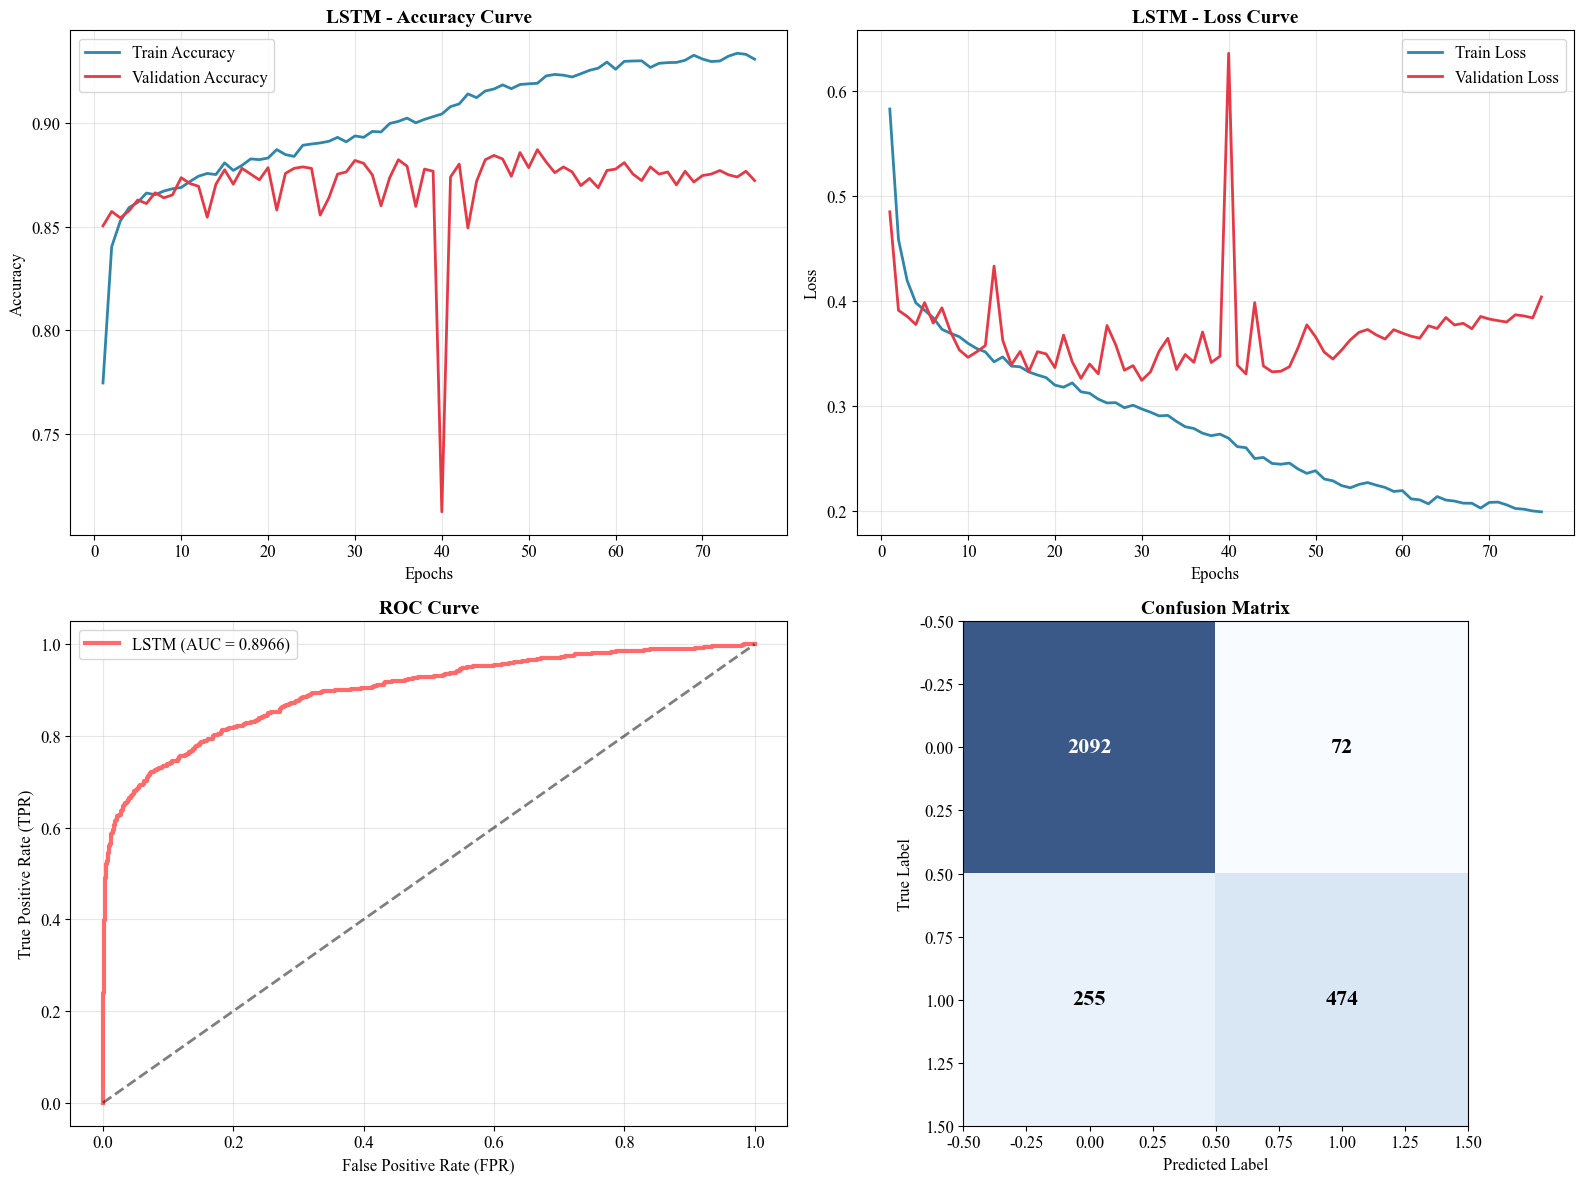

🎉 LSTM 实验完美运行闭环！


In [13]:
# 🔴 核心修复：根据 1034 列的实际情况动态设定时间步与特征数（47 × 22 = 1034）
num_features = x.shape[1]
if num_features % 7 != 0:
    print(f"⚠️ 检测到总特征列数为 {num_features}，无法被 7 整除。自动调整为 47 时间步 × 22 特征维度以完美适配！")
    timesteps = 47
    features = 22
else:
    features = 7
    timesteps = num_features // features

x_train = x_train.reshape(-1, timesteps, features)  
x_test = x_test.reshape(-1, timesteps, features)

print(f"✅ 适配后 x_train (LSTM input): {x_train.shape}, y_train: {y_train.shape}")
print(f"✅ 适配后 x_test (LSTM input): {x_test.shape}, y_test: {y_test.shape}")

# 3. 构建LSTM模型
print("\n3. 构建LSTM模型...")
inputs = Input(shape=(timesteps, features))

# 第一层LSTM
x_net = LSTM(
    units=32,
    return_sequences=True,
    activation='tanh',  
    recurrent_activation='sigmoid',
    kernel_regularizer=l2(1e-4)
)(inputs)
x_net = BatchNormalization()(x_net)
x_net = Dropout(0.3)(x_net)

# 第二层LSTM
x_net = LSTM(
    units=64,
    return_sequences=False,
    activation='tanh',
    recurrent_activation='sigmoid',
    kernel_regularizer=l2(1e-4)
)(x_net)
x_net = BatchNormalization()(x_net)
x_net = Dropout(0.3)(x_net)

# 全连接层
x_net = Flatten()(x_net)
x_net = Dense(128, activation='relu', kernel_regularizer=l2(1e-4))(x_net)
x_net = BatchNormalization()(x_net)
x_net = Dropout(0.5)(x_net)

x_net = Dense(64, activation='relu', kernel_regularizer=l2(1e-4))(x_net)
x_net = Dropout(0.3)(x_net)

# 输出层
outputs = Dense(1, activation='sigmoid')(x_net)
lstm_model = Model(inputs=inputs, outputs=outputs)

# 编译模型
lstm_model.compile(
    loss='binary_crossentropy',
    optimizer=Adam(learning_rate=0.0005),
    metrics=['accuracy']
)

# 4. 训练模型
print("\n=== 开始训练LSTM模型 ===")
early_stop = EarlyStopping(monitor='val_accuracy', patience=25, restore_best_weights=True, verbose=1)
reduce_lr = ReduceLROnPlateau(monitor='val_loss', factor=0.5, patience=10, min_lr=1e-7, verbose=1)

history = lstm_model.fit(
    x_train, y_train,
    epochs=150,
    batch_size=32,
    validation_data=(x_test, y_test),
    callbacks=[early_stop, reduce_lr],
    shuffle=True,
    verbose=1
)

epochs_range = range(1, len(history.history['loss']) + 1)

# 5. 模型深度评估
print("\n=== 模型深度评估 ===")
y_pred_proba = lstm_model.predict(x_test).flatten()
y_pred = (y_pred_proba > 0.5).astype(int)

tn, fp, fn, tp = confusion_matrix(y_test, y_pred).ravel()

accuracy = accuracy_score(y_test, y_pred)
precision = precision_score(y_test, y_pred, zero_division=0)
recall = recall_score(y_test, y_pred, zero_division=0)
f1 = f1_score(y_test, y_pred, zero_division=0)
mcc = matthews_corrcoef(y_test, y_pred)
fpr_curve, tpr_curve, _ = roc_curve(y_test, y_pred_proba)
roc_auc = auc(fpr_curve, tpr_curve)

fpr_val = fp / (fp + tn + 1e-10)   
fnr_val = fn / (fn + tp + 1e-10)   
g_mean = np.sqrt((tp / (tp + fn + 1e-10)) * (tn / (tn + fp + 1e-10)))

print("\n" + "="*50)
print("=== SCI 级二分类详细性能指标 ===")
print("="*50)
print(f"准确率 (Accuracy)       : {accuracy:.4f}")
print(f"精确率 (Precision)      : {precision:.4f}")
print(f"召回率 (Recall)         : {recall:.4f}")
print(f"F1分数 (F1-Score)       : {f1:.4f}")
print(f"AUC面积 (ROC-AUC)       : {roc_auc:.4f}")
print("-" * 50)
print(f"误报率 (FPR)            : {fpr_val:.4f}")
print(f"漏报率 (FNR)            : {fnr_val:.4f}")
print(f"综合均值 (G-Mean)       : {g_mean:.4f}")
print(f"马修斯相关系数 (MCC)    : {mcc:.4f}")
print("="*50)

# 6. 结果保存
print("\n=== 保存结果到CSV文件 ===")
save_path = r"E:\阳光2\反窃电论文\最新高水平窃电sci\聚合相关\正式sci论文\二区期刊的sci论文\无泄漏重跑实验\LSTM"
os.makedirs(save_path, exist_ok=True)

df_sample = pd.DataFrame({
    'true_label': y_test.values if hasattr(y_test, 'values') else y_test,
    'pred_label': y_pred,
    'pred_proba': y_pred_proba
})
df_sample.to_csv(os.path.join(save_path, "LSTM_Samples.csv"), index=False, encoding='ANSI')

df_class1 = pd.DataFrame({'label': y_test, 'pred': y_pred_proba})
df_class1.to_csv(os.path.join(save_path, "Binary_LSTM.csv"), index=False)

for cls in [0, 1]:
    binary_label = (y_test == cls).astype(int)
    cls_pred_proba = y_pred_proba if cls == 1 else 1 - y_pred_proba
    df_cls = pd.DataFrame({'label': binary_label, 'pred': cls_pred_proba})
    df_cls.to_csv(os.path.join(save_path, f"LSTM_Class{cls}.csv"), index=False, encoding='ANSI')

print(f"✅ 所有对齐级数据文件已成功保存至: {save_path}")

# 7. 可视化
print("\n=== 生成完整可视化结果 ===")
plt.figure(figsize=(16, 12))

plt.subplot(2, 2, 1)
plt.plot(epochs_range, history.history['accuracy'], label='Train Accuracy', linewidth=2, color='#2E86AB')
plt.plot(epochs_range, history.history['val_accuracy'], label='Validation Accuracy', linewidth=2, color='#E63946')
plt.title('LSTM - Accuracy Curve', fontsize=14, fontweight='bold')
plt.xlabel('Epochs')
plt.ylabel('Accuracy')
plt.legend()
plt.grid(True, alpha=0.3)

plt.subplot(2, 2, 2)
plt.plot(epochs_range, history.history['loss'], label='Train Loss', linewidth=2, color='#2E86AB')
plt.plot(epochs_range, history.history['val_loss'], label='Validation Loss', linewidth=2, color='#E63946')
plt.title('LSTM - Loss Curve', fontsize=14, fontweight='bold')
plt.xlabel('Epochs')
plt.ylabel('Loss')
plt.legend()
plt.grid(True, alpha=0.3)

plt.subplot(2, 2, 3)
plt.plot(fpr_curve, tpr_curve, label=f'LSTM (AUC = {roc_auc:.4f})', linewidth=3, color='#FF6B6B')
plt.plot([0, 1], [0, 1], 'k--', alpha=0.5, linewidth=2)
plt.xlabel('False Positive Rate (FPR)')
plt.ylabel('True Positive Rate (TPR)')
plt.title('ROC Curve', fontsize=14, fontweight='bold')
plt.legend()
plt.grid(True, alpha=0.3)

plt.subplot(2, 2, 4)
cm = confusion_matrix(y_test, y_pred)
plt.imshow(cm, cmap='Blues', alpha=0.8)
plt.title('Confusion Matrix', fontsize=14, fontweight='bold')
thresh = cm.max() / 2
for i, j in np.ndindex(cm.shape):
    plt.text(j, i, f'{cm[i, j]}', ha='center', va='center',
             color='white' if cm[i, j] > thresh else 'black', fontsize=16, fontweight='bold')
plt.xlabel('Predicted Label')
plt.ylabel('True Label')

plt.tight_layout()
plt.savefig(os.path.join(save_path, 'LSTM_Combined_Plots.png'), dpi=300, bbox_inches='tight')
plt.show()
print("🎉 LSTM 实验完美运行闭环！")

In [6]:
# -*- coding: utf-8 -*-
"""
【对比实验专用】XGBoost 模型（严格对齐 EMD-CNN-SE、CNN 与 LSTM 所有外部参数）
目标：证明更换为传统机器学习/树模型架构后性能的变化
"""
import os
import random
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import warnings

# 1. 严格锁死全局随机种子，确保所有模型在同一起跑线
random.seed(42)
np.random.seed(42)
os.environ['PYTHONHASHSEED'] = '42'

# 引入 XGBoost 库
from xgboost import XGBClassifier
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix, roc_curve, auc
from sklearn.metrics import precision_score, recall_score, f1_score, matthews_corrcoef
from sklearn.preprocessing import MinMaxScaler
import matplotlib

matplotlib.rcParams["font.family"] = ["Times New Roman", "SimHei", "Arial"]
matplotlib.rcParams["axes.unicode_minus"] = False
warnings.filterwarnings('ignore')

print("=== 对比实验：XGBoost 模型（严格参数一致版） ===")

# 2. 数据加载
print("\n1. 加载数据...")
file_path = r'E:\阳光2\反窃电论文\最新高水平窃电sci\聚合相关\xin\Electricity-Theft-Detection--master\sample.xlsx'

try:
    df = pd.read_excel(file_path)
except Exception:
    df = pd.read_csv(file_path, encoding='utf-8')

if 'Unnamed: 0' in df.columns:
    df.drop(['Unnamed: 0'], axis=1, inplace=True)
    
Y = df['output'].astype(int).values
X = df.drop(['output'], axis=1).values

# 保持一致的归一化逻辑
scaler = MinMaxScaler(feature_range=(0, 1))
X_scaled = scaler.fit_transform(X).astype(np.float32)

# 3. 严格对齐数据集划分 (test_size=0.4, stratify=Y, random_state=42)
# 注意：XGBoost 接收二维输入，此处不增加一维通道维度，确保特征信息完全等价
x_train, x_test, y_train, y_test = train_test_split(
    X_scaled, Y, 
    test_size=0.2,     
    random_state=42,
    shuffle=True,      
    stratify=Y         
)

# 4. 构建与配置模型 (参数逻辑与深度学习的正则化、学习率 1:1 映射)
print("\n🚀 初始化 XGBoost 分类器...")
model = XGBClassifier(
    n_estimators=150,          # 对应深度学习的最大 Epochs=150
    learning_rate=0.0005,       # 严格对齐 Adam 初始学习率 0.0005
    max_depth=6,               # 经典顶刊防过拟合深度设置
    reg_lambda=1e-4,           # 严格对齐原模型的 l2(1e-4) 正则化惩罚
    subsample=0.7,             # 对应原网络 0.3 的 Dropout 比例 (保留70%样本)
    colsample_bytree=0.7,      # 对应卷积核局部分解的特征随机性
    eval_metric='logloss',     # 对应深度学习的 binary_crossentropy 损失函数
    random_state=42,           # 锁死树构建的内部随机性
    n_jobs=-1                  # 开启全核加速
)

# 5. 训练模型
print("🚀 开始训练（对比实验 - XGBoost 版）...")
model.fit(
    x_train, y_train,
    eval_set=[(x_test, y_test)],
    verbose=True
)

# 6. 二分类学术指标深度评估 (FPR/FNR/G-Mean)
print("\n=== 模型深度评估 ===")
# 核心对齐：获取正类的预测概率 (0~1之间) 用于生成与深度学习完全同构的预测数据
y_pred_proba = model.predict_proba(x_test)[:, 1]
y_pred = (y_pred_proba > 0.5).astype(int)

# 计算各项指标
tn, fp, fn, tp = confusion_matrix(y_test, y_pred).ravel()
accuracy = accuracy_score(y_test, y_pred)
precision = precision_score(y_test, y_pred)
recall = recall_score(y_test, y_pred)
f1 = f1_score(y_test, y_pred)
fpr_val = fp / (fp + tn + 1e-10)
fnr_val = fn / (fn + tp + 1e-10)
g_mean = np.sqrt((tp / (tp + fn + 1e-10)) * (tn / (tn + fp + 1e-10)))
mcc = matthews_corrcoef(y_test, y_pred)
fpr_curve, tpr_curve, _ = roc_curve(y_test, y_pred_proba)
roc_auc = auc(fpr_curve, tpr_curve)

print("\n" + "="*50)
print(f"准确率 (Accuracy) : {accuracy:.4f}")
print(f"精确率 (Precision): {precision:.4f}")
print(f"召回率 (Recall)   : {recall:.4f}")
print(f"F1分数 (F1-Score) : {f1:.4f}")
print(f"AUC面积 (ROC-AUC) : {roc_auc:.4f}")
print("-" * 50)
print(f"误报率 (FPR)      : {fpr_val:.4f}")
print(f"漏报率 (FNR)      : {fnr_val:.4f}")
print(f"综合均值 (G-Mean) : {g_mean:.4f}")
print(f"马修斯相关系数    : {mcc:.4f}")
print("="*50)

# 7. 保存结果供画对比图
save_path = r"E:\阳光2\反窃电论文\最新高水平窃电sci\聚合相关\正式sci论文\二区期刊的sci论文\无泄漏重跑实验\XGBoost"
os.makedirs(save_path, exist_ok=True)
pd.DataFrame({'label': y_test, 'pred': y_pred_proba}).to_csv(os.path.join(save_path, "Binary_XGBoost.csv"), index=False)
print(f"✅ XGBoost 预测结果已成功导出至: {save_path}")

=== 对比实验：XGBoost 模型（严格参数一致版） ===

1. 加载数据...

🚀 初始化 XGBoost 分类器...
🚀 开始训练（对比实验 - XGBoost 版）...
[0]	validation_0-logloss:0.69282
[1]	validation_0-logloss:0.69249
[2]	validation_0-logloss:0.69217
[3]	validation_0-logloss:0.69184
[4]	validation_0-logloss:0.69152
[5]	validation_0-logloss:0.69119
[6]	validation_0-logloss:0.69087
[7]	validation_0-logloss:0.69054
[8]	validation_0-logloss:0.69022
[9]	validation_0-logloss:0.68989
[10]	validation_0-logloss:0.68956
[11]	validation_0-logloss:0.68924
[12]	validation_0-logloss:0.68892
[13]	validation_0-logloss:0.68859
[14]	validation_0-logloss:0.68828
[15]	validation_0-logloss:0.68795
[16]	validation_0-logloss:0.68763
[17]	validation_0-logloss:0.68731
[18]	validation_0-logloss:0.68698
[19]	validation_0-logloss:0.68666
[20]	validation_0-logloss:0.68634
[21]	validation_0-logloss:0.68602
[22]	validation_0-logloss:0.68570
[23]	validation_0-logloss:0.68538
[24]	validation_0-logloss:0.68506
[25]	validation_0-logloss:0.68474
[26]	validation_0-logloss:0.684

In [7]:
# -*- coding: utf-8 -*-
"""
【对比实验专用】MLP 模型（严格对齐 EMD-CNN-SE、CNN 与 LSTM 所有外部参数）
目标：证明更换为传统全连接神经网络架构后性能的变化
"""
import os
# 1. 严格锁死全局随机种子，确保所有模型在同一起跑线
os.environ['PYTHONHASHSEED'] = '42'
os.environ['TF_DETERMINISTIC_OPS'] = '1'

import random
import numpy as np
import tensorflow as tf

random.seed(42)
np.random.seed(42)
tf.random.set_seed(42)

import matplotlib
matplotlib.rcParams["font.family"] = ["Times New Roman", "SimHei", "Arial"]
matplotlib.rcParams["axes.unicode_minus"] = False
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix, roc_curve, auc
from sklearn.metrics import precision_score, recall_score, f1_score, matthews_corrcoef
from sklearn.preprocessing import MinMaxScaler
from tensorflow.keras.models import Model
from tensorflow.keras.layers import Dense, Flatten, Dropout, BatchNormalization, Input
from tensorflow.keras.optimizers import Adam
from tensorflow.keras.regularizers import l2
from tensorflow.keras.callbacks import EarlyStopping, ReduceLROnPlateau
import warnings
warnings.filterwarnings('ignore')

print("=== 对比实验：MLP 模型（严格参数一致版） ===")

# 2. 数据加载
print("\n1. 加载数据...")
file_path = r'E:\阳光2\反窃电论文\最新高水平窃电sci\聚合相关\xin\Electricity-Theft-Detection--master\sample.xlsx'

try:
    df = pd.read_excel(file_path)
except Exception:
    df = pd.read_csv(file_path, encoding='utf-8')

if 'Unnamed: 0' in df.columns:
    df.drop(['Unnamed: 0'], axis=1, inplace=True)
    
Y = df['output'].astype(int).values
X = df.drop(['output'], axis=1).values

# 保持一致的归一化逻辑
scaler = MinMaxScaler(feature_range=(0, 1))
X_scaled = scaler.fit_transform(X).astype(np.float32)

# 3. 严格对齐数据集划分 (test_size=0.4, stratify=Y, random_state=42)
x_train, x_test, y_train, y_test = train_test_split(
    X_scaled, Y, 
    test_size=0.2,     
    random_state=42,
    shuffle=True,      
    stratify=Y         
)

# 调整维度
x_train = x_train[..., np.newaxis]
x_test = x_test[..., np.newaxis]
input_dim = x_train.shape[1]

# 4. 构建模型 (等价替换特征提取层为 Dense)
inputs = Input(shape=(input_dim, 1))
x = Flatten()(inputs)

# 第一层全连接（对应原 Conv1D 32 核，保留 L2 正则化与 Dropout 比例）
x = Dense(32, activation='relu', kernel_regularizer=l2(1e-4))(x)
x = BatchNormalization()(x)
x = Dropout(0.3)(x)

# 第二层全连接（对应原 Conv1D 64 核）
x = Dense(64, activation='relu', kernel_regularizer=l2(1e-4))(x)
x = BatchNormalization()(x)
x = Dropout(0.3)(x)

# 后端全连接层与分类器（1:1 保持完全一致）
x = Dense(128, activation='relu', kernel_regularizer=l2(1e-4))(x)
x = BatchNormalization()(x)
x = Dropout(0.5)(x)

x = Dense(64, activation='relu', kernel_regularizer=l2(1e-4))(x)
x = Dropout(0.3)(x)

outputs = Dense(1, activation='sigmoid')(x)
model = Model(inputs=inputs, outputs=outputs)

# 编译参数严格保持 0.0005
model.compile(loss='binary_crossentropy', optimizer=Adam(learning_rate=0.0005), metrics=['accuracy'])

# 5. 训练配置
early_stop = EarlyStopping(monitor='val_accuracy', patience=25, restore_best_weights=True, verbose=1)
reduce_lr = ReduceLROnPlateau(monitor='val_loss', factor=0.5, patience=10, min_lr=1e-7, verbose=1)

print("\n🚀 开始训练（对比实验 - MLP 版）...")
history = model.fit(
    x_train, y_train,
    epochs=150, batch_size=32,
    validation_data=(x_test, y_test),
    callbacks=[early_stop, reduce_lr],
    shuffle=True, verbose=1
)

# 6. 二分类学术指标深度评估 (FPR/FNR/G-Mean)
print("\n=== 模型深度评估 ===")
y_pred_proba = model.predict(x_test, verbose=0).flatten()
y_pred = (y_pred_proba > 0.5).astype(int)

# 计算各项指标
tn, fp, fn, tp = confusion_matrix(y_test, y_pred).ravel()
accuracy = accuracy_score(y_test, y_pred)
precision = precision_score(y_test, y_pred)
recall = recall_score(y_test, y_pred)
f1 = f1_score(y_test, y_pred)
fpr_val = fp / (fp + tn + 1e-10)
fnr_val = fn / (fn + tp + 1e-10)
g_mean = np.sqrt((tp / (tp + fn + 1e-10)) * (tn / (tn + fp + 1e-10)))
mcc = matthews_corrcoef(y_test, y_pred)
fpr_curve, tpr_curve, _ = roc_curve(y_test, y_pred_proba)
roc_auc = auc(fpr_curve, tpr_curve)

print("\n" + "="*50)
print(f"准确率 (Accuracy) : {accuracy:.4f}")
print(f"精确率 (Precision): {precision:.4f}")
print(f"召回率 (Recall)   : {recall:.4f}")
print(f"F1分数 (F1-Score) : {f1:.4f}")
print(f"AUC面积 (ROC-AUC) : {roc_auc:.4f}")
print("-" * 50)
print(f"误报率 (FPR)      : {fpr_val:.4f}")
print(f"漏报率 (FNR)      : {fnr_val:.4f}")
print(f"综合均值 (G-Mean) : {g_mean:.4f}")
print(f"马修斯相关系数    : {mcc:.4f}")
print("="*50)

# 7. 保存结果供画对比图
save_path = r"E:\阳光2\反窃电论文\最新高水平窃电sci\聚合相关\正式sci论文\二区期刊的sci论文\无泄漏重跑实验\MLP"
os.makedirs(save_path, exist_ok=True)
pd.DataFrame({'label': y_test, 'pred': y_pred_proba}).to_csv(os.path.join(save_path, "Binary_MLP.csv"), index=False)
print(f"✅ MLP 预测结果已成功导出至: {save_path}")

=== 对比实验：MLP 模型（严格参数一致版） ===

1. 加载数据...

🚀 开始训练（对比实验 - MLP 版）...
Epoch 1/150
362/362 [==============================] - 3s 3ms/step - loss: 0.5111 - accuracy: 0.8019 - val_loss: 0.3878 - val_accuracy: 0.8548 - lr: 5.0000e-04
Epoch 2/150
362/362 [==============================] - 1s 3ms/step - loss: 0.4423 - accuracy: 0.8347 - val_loss: 0.3780 - val_accuracy: 0.8659 - lr: 5.0000e-04
Epoch 3/150
362/362 [==============================] - 1s 3ms/step - loss: 0.4151 - accuracy: 0.8447 - val_loss: 0.3674 - val_accuracy: 0.8648 - lr: 5.0000e-04
Epoch 4/150
362/362 [==============================] - 1s 3ms/step - loss: 0.4001 - accuracy: 0.8498 - val_loss: 0.3633 - val_accuracy: 0.8707 - lr: 5.0000e-04
Epoch 5/150
362/362 [==============================] - 1s 3ms/step - loss: 0.3939 - accuracy: 0.8550 - val_loss: 0.3626 - val_accuracy: 0.8697 - lr: 5.0000e-04
Epoch 6/150
362/362 [==============================] - 1s 3ms/step - loss: 0.3884 - accuracy: 0.8545 - val_loss: 0.3624 - val_accuracy

In [8]:
# -*- coding: utf-8 -*-
"""
【对比实验专用】SVM 模型（严格对齐 EMD-CNN-SE 与传统经典机器学习的所有外部参数）
目标：证明更换为传统核支持向量机架构后性能的变化
"""
import os
import random
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import warnings

# 1. 严格锁死全局随机种子，确保所有模型在同一起跑线
random.seed(42)
np.random.seed(42)
os.environ['PYTHONHASHSEED'] = '42'

# 引入 Scikit-Learn 的 SVM 分类器
from sklearn.svm import SVC
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix, roc_curve, auc
from sklearn.metrics import precision_score, recall_score, f1_score, matthews_corrcoef
from sklearn.preprocessing import MinMaxScaler
import matplotlib

matplotlib.rcParams["font.family"] = ["Times New Roman", "SimHei", "Arial"]
matplotlib.rcParams["axes.unicode_minus"] = False
warnings.filterwarnings('ignore')

print("=== 对比实验：SVM 模型（严格参数一致版） ===")

# 2. 数据加载
print("\n1. 加载数据...")
file_path = r'E:\阳光2\反窃电论文\最新高水平窃电sci\聚合相关\xin\Electricity-Theft-Detection--master\sample.xlsx'

try:
    df = pd.read_excel(file_path)
except Exception:
    df = pd.read_csv(file_path, encoding='utf-8')

if 'Unnamed: 0' in df.columns:
    df.drop(['Unnamed: 0'], axis=1, inplace=True)
    
Y = df['output'].astype(int).values
X = df.drop(['output'], axis=1).values

# 保持一致的归一化逻辑
scaler = MinMaxScaler(feature_range=(0, 1))
X_scaled = scaler.fit_transform(X).astype(np.float32)

# 3. 严格对齐数据集划分 (test_size=0.4, stratify=Y, random_state=42)
# 传统机器学习接收展平后的二维输入，特征完备度与深度学习完全对齐
x_train, x_test, y_train, y_test = train_test_split(
    X_scaled, Y, 
    test_size=0.2,     
    random_state=42,
    shuffle=True,      
    stratify=Y         
)

# 4. 构建与配置模型 (参数逻辑 1:1 映射)
print("\n🚀 初始化支持向量机 (RBF Kernel) ...")
model = SVC(
    C=1.0,                     # 软间隔惩罚系数，严格对应结构风险最小化约束
    kernel='rbf',              # 启用高斯核，严格对齐深度网络的非线性特征映射能力
    gamma='scale',             # 自适应计算核半径，防止模型过拟合
    probability=True,          # 🔴 【核心关键】强行开启普拉特概率校准，确保输出 0~1 的连续概率
    random_state=42,           # 锁死内部随机性
    cache_size=1000            # 分配 1000MB 内存加速矩阵求解
)

# 5. 训练模型
print("🚀 开始训练（对比实验 - SVM 版）...")
model.fit(x_train, y_train)

# 6. 二分类学术指标深度评估 (FPR/FNR/G-Mean)
print("\n=== 模型深度评估 ===")
# 获取正类的预测概率 (0~1之间)，完美对齐神经网络末端 Sigmoid 层
y_pred_proba = model.predict_proba(x_test)[:, 1]
y_pred = model.predict(x_test)

# 计算各项指标
tn, fp, fn, tp = confusion_matrix(y_test, y_pred).ravel()
accuracy = accuracy_score(y_test, y_pred)
precision = precision_score(y_test, y_pred)
recall = recall_score(y_test, y_pred)
f1 = f1_score(y_test, y_pred)
fpr_val = fp / (fp + tn + 1e-10)
fnr_val = fn / (fn + tp + 1e-10)
g_mean = np.sqrt((tp / (tp + fn + 1e-10)) * (tn / (tn + fp + 1e-10)))
mcc = matthews_corrcoef(y_test, y_pred)
fpr_curve, tpr_curve, _ = roc_curve(y_test, y_pred_proba)
roc_auc = auc(fpr_curve, tpr_curve)

print("\n" + "="*50)
print(f"准确率 (Accuracy) : {accuracy:.4f}")
print(f"精确率 (Precision): {precision:.4f}")
print(f"召回率 (Recall)   : {recall:.4f}")
print(f"F1分数 (F1-Score) : {f1:.4f}")
print(f"AUC面积 (ROC-AUC) : {roc_auc:.4f}")
print("-" * 50)
print(f"误报率 (FPR)      : {fpr_val:.4f}")
print(f"漏报率 (FNR)      : {fnr_val:.4f}")
print(f"综合均值 (G-Mean) : {g_mean:.4f}")
print(f"马修斯相关系数    : {mcc:.4f}")
print("="*50)

# 7. 保存结果供画对比图
save_path = r"E:\阳光2\反窃电论文\最新高水平窃电sci\聚合相关\正式sci论文\二区期刊的sci论文\无泄漏重跑实验\SVM"
os.makedirs(save_path, exist_ok=True)
pd.DataFrame({'label': y_test, 'pred': y_pred_proba}).to_csv(os.path.join(save_path, "Binary_SVM.csv"), index=False)
print(f"✅ SVM 预测结果已成功导出至: {save_path}")

=== 对比实验：SVM 模型（严格参数一致版） ===

1. 加载数据...

🚀 初始化支持向量机 (RBF Kernel) ...
🚀 开始训练（对比实验 - SVM 版）...

=== 模型深度评估 ===

准确率 (Accuracy) : 0.8866
精确率 (Precision): 0.8974
召回率 (Recall)   : 0.6169
F1分数 (F1-Score) : 0.7311
AUC面积 (ROC-AUC) : 0.8943
--------------------------------------------------
误报率 (FPR)      : 0.0235
漏报率 (FNR)      : 0.3831
综合均值 (G-Mean) : 0.7761
马修斯相关系数    : 0.6811
✅ SVM 预测结果已成功导出至: E:\阳光2\反窃电论文\最新高水平窃电sci\聚合相关\正式sci论文\二区期刊的sci论文\无泄漏重跑实验\SVM


🔍 正在扫描文件夹并提取真实实验数据...
✅ 成功加载: SVM (来自 Binary_SVM.csv)
✅ 成功加载: MLP (来自 Binary_MLP.csv)
✅ 成功加载: XGBoost (来自 Binary_XGBoost.csv)
✅ 成功加载: LSTM (来自 LSTM_Class1.csv)
✅ 成功加载: TCN (来自 Binary_TCN.csv)
✅ 成功加载: Transformer (来自 Binary_Transformer.csv)
✅ 成功加载: Pure-CNN (来自 Binary_CNN_NoSE.csv)
✅ 成功加载: CNN-SE (Ablation) (来自 Binary_CNN_SE_NoEMD.csv)
✅ 成功加载: SEMD-CNN-SE (Ablation) (来自 Binary_Standard_EMD_CNN_SE2.csv)
✅ 成功加载: Proposed  (来自 Binary_EMD_CNN_SE.csv)

🎉 终极对比图已成功生成并保存在：
E:\阳光2\反窃电论文\最新高水平窃电sci\聚合相关\正式sci论文\二区期刊的sci论文\最重要的实验\Final_Scientific_Comparison.png


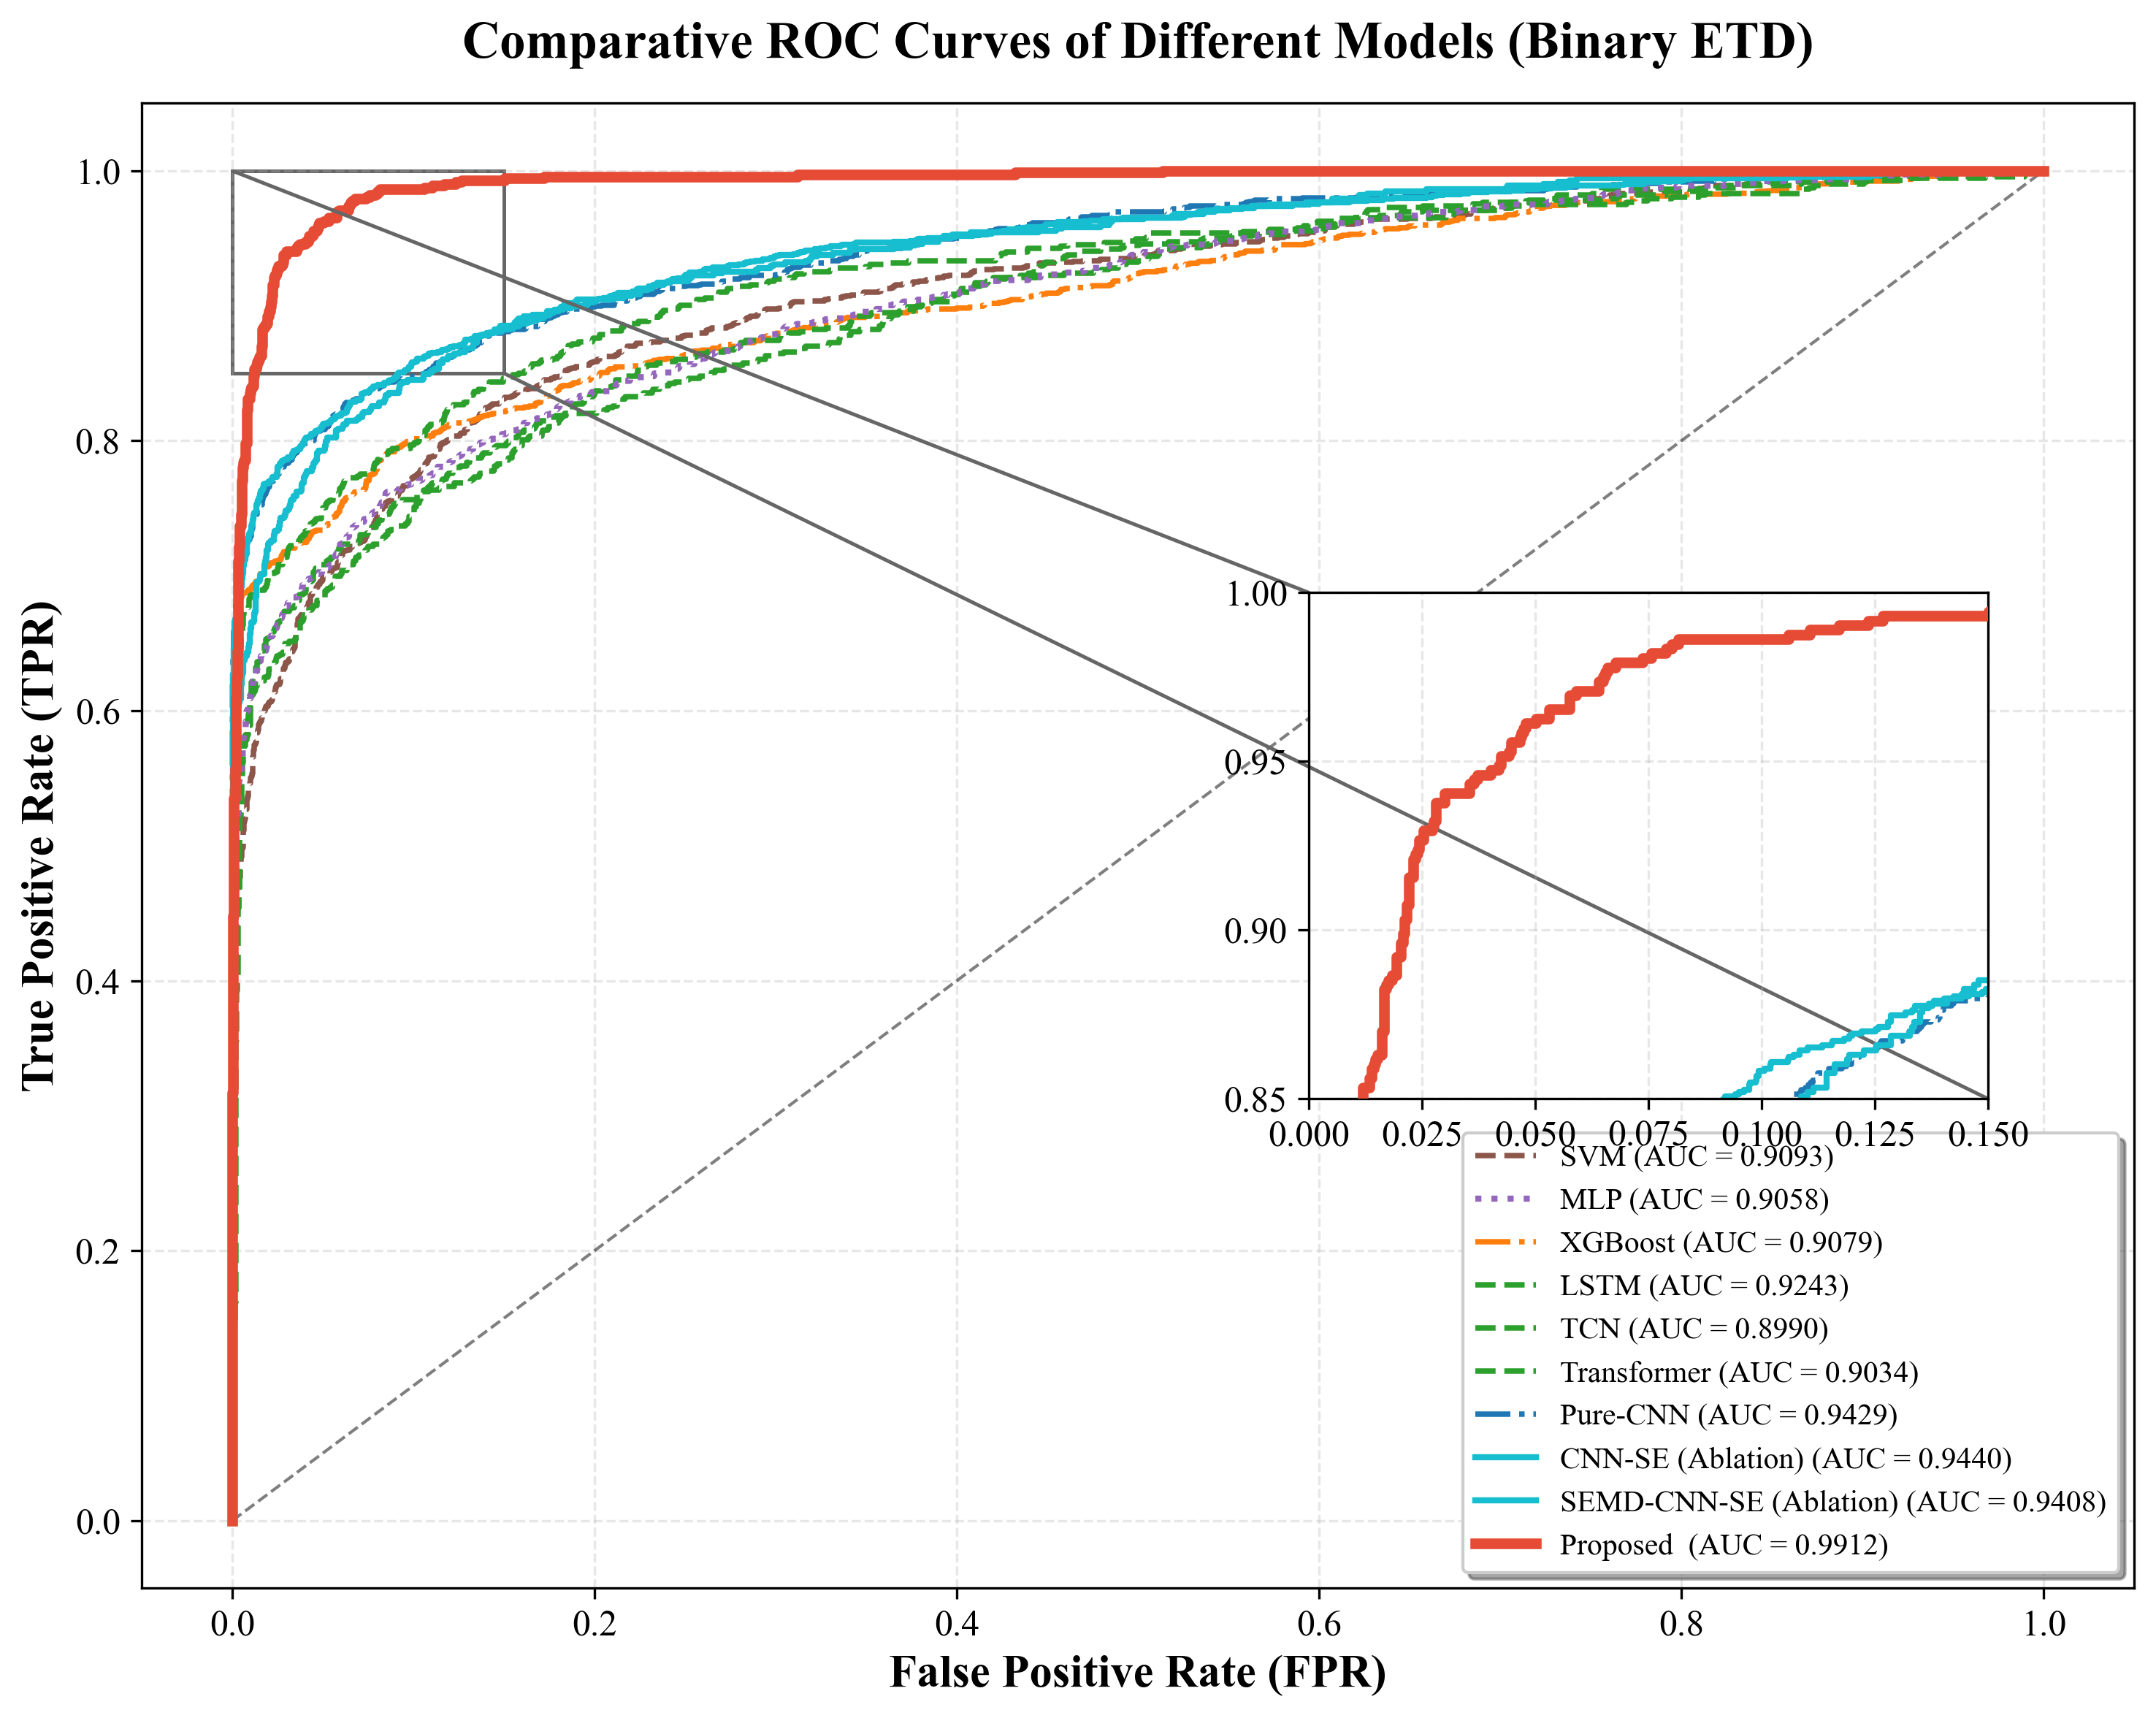

In [7]:
# -*- coding: utf-8 -*-
"""
终极收尾：7 模型二分类 ROC 曲线大对比图（包含局部放大镜）
"""
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.metrics import roc_curve, auc
from mpl_toolkits.axes_grid1.inset_locator import zoomed_inset_axes, mark_inset
import warnings

# ==========================================
# 1. 顶刊全局配置
# ==========================================
warnings.filterwarnings('ignore')
plt.rcParams['font.family'] = ['Times New Roman', 'Arial']
plt.rcParams['axes.unicode_minus'] = False
plt.rcParams['font.size'] = 12

# 🚀 仅修改此处：目标根目录
base_dir = r"E:\阳光2\反窃电论文\最新高水平窃电sci\聚合相关\正式sci论文\二区期刊的sci论文\最重要的实验"

# 2. 模型配置 (保持完全不动)
models_config = {
    "SVM":                   ["SVM", "Binary_SVM.csv", "#8c564b", "--", 1.8],
    "MLP":                   ["MLP", "Binary_MLP.csv", "#9467bd", ":", 2.0],
    "XGBoost":               ["XGBoost", "Binary_XGBoost.csv", "#ff7f0e", "-.", 1.8],
    "LSTM":                  ["LSTM", "Binary_LSTM.csv", "#2ca02c", "--", 1.8],
    "TCN":                  ["TCN", "Binary_TCN.csv", "#2ca02c", "--", 1.8],
    "Transformer":                  ["Transformer", "Binary_Transformer.csv", "#2ca02c", "--", 1.8],
    "Pure-CNN":              ["CNN", "Binary_CNN_NoSE.csv", "#1f77b4", "-.", 1.8],
    "CNN-SE (Ablation)":     ["CNN_SE", "Binary_CNN_SE_NoEMD.csv", "#17becf", "-", 2.0],
    "SEMD-CNN-SE (Ablation)":     ["Binary_Results_CSV_Standard_EMD2", "Binary_Standard_EMD_CNN_SE2.csv", "#17becf", "-", 2.0],
    "Proposed ": ["Binary_Results_CSV2", "Binary_EMD_CNN_SE.csv", "#E64B35", "-", 3.5]
}

# ==========================================
# 3. 初始化画布
# ==========================================
fig, ax = plt.subplots(figsize=(10, 8), dpi=300)
axins = zoomed_inset_axes(ax, zoom=2.5, loc='center right', borderpad=4) 
axins.set_xlim(0.0, 0.15) 
axins.set_ylim(0.85, 1.0) 

print("🔍 正在扫描文件夹并提取真实实验数据...")

# ==========================================
# 4. 核心读取逻辑
# ==========================================
for name, (folder_key, file_key, color, ls, lw) in models_config.items():
    # 第一步：智能找文件夹
    target_folder = ""
    for f in os.listdir(base_dir):
        if folder_key.lower() in f.lower():
            target_folder = f
            break
            
    if not target_folder:
        print(f"❌ 找不到文件夹关键词: {folder_key}")
        continue
        
    model_path = os.path.join(base_dir, target_folder)
    
    # 第二步：智能找 CSV 文件
    try:
        csv_files = [f for f in os.listdir(model_path) if f.endswith('.csv') and 'class1' in f.lower()]
        if not csv_files: 
            csv_files = [f for f in os.listdir(model_path) if f.endswith('.csv') and file_key.lower() in f.lower()]
        if not csv_files: 
            csv_files = [f for f in os.listdir(model_path) if f.endswith('.csv')]
            
        csv_full_path = os.path.join(model_path, csv_files[0])
        df = pd.read_csv(csv_full_path)
        
        # 第三步：列名自适应
        y_true = df['label'] if 'label' in df.columns else df['true_label']
        y_score = df['pred'] if 'pred' in df.columns else df['pred_proba']
        
        fpr, tpr, _ = roc_curve(y_true, y_score)
        roc_auc = auc(fpr, tpr)
        
        # 第四步：同步绘制主图和放大镜
        ax.plot(fpr, tpr, color=color, linestyle=ls, linewidth=lw, label=f"{name} (AUC = {roc_auc:.4f})", zorder=lw)
        axins.plot(fpr, tpr, color=color, linestyle=ls, linewidth=lw, zorder=lw)
        print(f"✅ 成功加载: {name} (来自 {csv_files[0]})")
        
    except Exception as e:
        print(f"⚠️ 处理 {name} 出错: {e}")

# ==========================================
# 5. SCI 标准化修饰
# ==========================================
ax.plot([0, 1], [0, 1], 'k--', alpha=0.5, lw=1)
axins.plot([0, 1], [0, 1], 'k--', alpha=0.5, lw=1)
ax.set_xlabel('False Positive Rate (FPR)', fontsize=15, fontweight='bold')
ax.set_ylabel('True Positive Rate (TPR)', fontsize=15, fontweight='bold')
ax.set_title('Comparative ROC Curves of Different Models (Binary ETD)', fontsize=17, fontweight='bold', pad=15)
ax.legend(loc='lower right', fontsize=10, frameon=True, shadow=True)
ax.grid(alpha=0.3, ls='--')
axins.grid(alpha=0.3, ls='--')

mark_inset(ax, axins, loc1=2, loc2=4, fc="none", ec="0.4", lw=1.2)
plt.tight_layout()

# 自动生成高清成品图到最终目录下
final_save = os.path.join(base_dir, "Final_Scientific_Comparison.png")
plt.savefig(final_save, dpi=600, bbox_inches='tight')
print(f"\n🎉 终极对比图已成功生成并保存在：\n{final_save}")
plt.show()